# Session 4 lecture: Descriptive statistics and distributions

<p class="lead">
One number never describes a column. This lecture shows how to summarise a variable with the right centre, the right spread and an honest picture of its shape, and how to tell a real extreme value from a mistake.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/04_descriptive_statistics_lecture.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## Recap quiz

Before we start, answer the quiz at the end of the [Session 3 lecture](03_cleaning_and_preparing_lecture.md). Write short answers; we discuss them together.

---

## What you will be able to explain

1. When the **mean**, the **median** or the **mode** is the right "typical value".
2. How **range**, **IQR**, **standard deviation** and **percentiles** describe spread, and which ones resist extreme values.
3. What **skew** and a **long tail** are, and how to spot them from the mean and median alone.
4. How to read a **histogram**, a **box plot** and an **ECDF**, and what each can hide.
5. What a **z-score** says, and why the normal curve is a **reference**, not an assumption.
6. How the **IQR rule** flags unusual values, and why we **flag** them instead of deleting them.

This lecture builds on [How statistics can mislead](../foundations/misleading-statistics.md), especially the section on averages. In the **Lab** you apply every idea to the retail orders and to US house prices.

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. Write your guess down first. **Check your understanding** boxes are short questions to answer in your own words.

Run the setup cell first. Later we also use **numpy**, Python's library for numbers, to simulate small example datasets. A fixed **seed** makes the "random" numbers the same every time you run the notebook, so your output matches everyone else's.

In [1]:
# Course data setup. Run this cell first; you do not need to understand it yet.
# It downloads the Superstore sample from Tableau's website, checks it is the
# exact version this course was written for, and prepares the order-lines table.
import hashlib
import os
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd

SOURCE_URL = "https://public.tableau.com/app/sample-data/sample_-_superstore.xls"
EXPECTED_SHA256 = "5045ed4fec49cae2cc0dfc5ab0d204ba09efa767fe00c996822499e8cc42fbbd"
SOURCE_FILE = os.environ.get("COURSE_XLS_PATH", "sample_-_superstore.xls")

try:
    import xlrd  # noqa: F401  (needed to read .xls files)
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xlrd"])

if not os.path.exists(SOURCE_FILE):
    urllib.request.urlretrieve(SOURCE_URL, SOURCE_FILE)

with open(SOURCE_FILE, "rb") as f:
    digest = hashlib.sha256(f.read()).hexdigest()
if digest != EXPECTED_SHA256:
    print("WARNING: Tableau has changed this sample file since the course was written.")
    print("Your numbers will differ from the lesson. Ask your facilitator for the course copy.")


def load_orders():
    """Return one row per order line, orders placed 2023-01-01 to 2025-12-31."""
    raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
    returns = pd.read_excel(SOURCE_FILE, sheet_name="Returns")

    # Orders with more than one Customer ID (a known data issue), found before filtering.
    ids_per_order = raw.groupby("Order ID")["Customer ID"].nunique()
    conflict_orders = set(ids_per_order[ids_per_order > 1].index)

    in_scope = (raw["Order Date"] >= "2023-01-01") & (raw["Order Date"] < "2026-01-01")
    df = raw.loc[in_scope].copy()

    df = df.rename(columns={
        "Row ID": "row_id", "Order ID": "order_id", "Order Date": "order_date",
        "Ship Date": "ship_date", "Ship Mode": "ship_mode", "Customer ID": "customer_id",
        "Segment": "segment", "Country/Region": "country_region", "Region": "region",
        "Category": "category", "Sub-Category": "sub_category", "Product ID": "product_id",
        "Product Name": "product_name", "Sales": "sales", "Quantity": "quantity",
        "Discount": "discount", "Profit": "profit",
    })
    df["returned_order_flag"] = df["order_id"].isin(set(returns["Order ID"])).astype(int)
    df["customer_order_conflict"] = df["order_id"].isin(conflict_orders).astype(int)
    df["customer_analysis_eligible"] = 1 - df["customer_order_conflict"]
    df["order_to_ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
    df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

    columns = [
        "row_id", "order_id", "order_date", "ship_date", "ship_mode", "customer_id",
        "segment", "country_region", "region", "category", "sub_category", "product_id",
        "product_name", "sales", "quantity", "discount", "profit", "returned_order_flag",
        "customer_analysis_eligible", "customer_order_conflict", "order_to_ship_days",
        "order_month",
    ]
    return df[columns].sort_values("row_id").reset_index(drop=True)


pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Setup complete.")

Setup complete.


In [2]:
import numpy as np

rng = np.random.default_rng(seed=42)
df = load_orders()
print("Order lines:", len(df))

Order lines: 6815


---

## Part 1: The centre — mean, median and mode

There are three common answers to "what is a typical value?":

| Measure | How it is found | Good for |
|---|---|---|
| **Mean** (average) | Add all values, divide by how many | Totals and planning: mean × count = total |
| **Median** | The middle value once values are sorted | "A typical case" when a few values are extreme |
| **Mode** | The most frequent value | Categories, and counts with few possible values |

### Predict, then reveal: one very large salary

A small team has nine salaries. Then the company owner, who pays themself far more, is added to the list.

> **Predict, then reveal**
>
> When the owner is added, which moves more: the **mean** or the **median**? Write down your guess, then run the next cell.

In [3]:
team = pd.Series([31, 33, 34, 35, 36, 38, 40, 41, 44], name="salary (thousands)")
with_owner = pd.concat([team, pd.Series([400])], ignore_index=True)

print("Team only:   mean", round(team.mean(), 1), "| median", team.median())
print("With owner:  mean", round(with_owner.mean(), 1), "| median", with_owner.median())

Team only:   mean 36.9 | median 36.0
With owner:  mean 73.2 | median 37.0


One extreme value dragged the mean far away from every real team member, while the median barely moved. The median **resists** extreme values; statisticians call this being **robust**.

The mean is not wrong. If the question is "what will the payroll cost?", the mean (times the head count) gives the total. If the question is "what does a typical person earn?", the median is the honest answer.

### The mode

For a category, the only sensible "typical value" is the most frequent one. `value_counts()` lists every category with its count; `mode()` returns the most frequent:

In [4]:
print(df["ship_mode"].value_counts())
print("Mode:", df["ship_mode"].mode()[0])

ship_mode
Standard Class    4171
Second Class      1313
First Class        972
Same Day           359
Name: count, dtype: int64
Mode: Standard Class


> **Check your understanding 1**
>
> 1. A manager says "our average customer spends a lot". Which two questions would you ask before believing it?
> 2. Why can you not compute a mean or a median of `ship_mode`? Which level of measurement from Session 2 explains this?

---

## Part 2: Spread — how different are the values?

Two delivery services can have the same average delivery time and still feel very different to customers. Here are two simulated services, each with 500 deliveries:

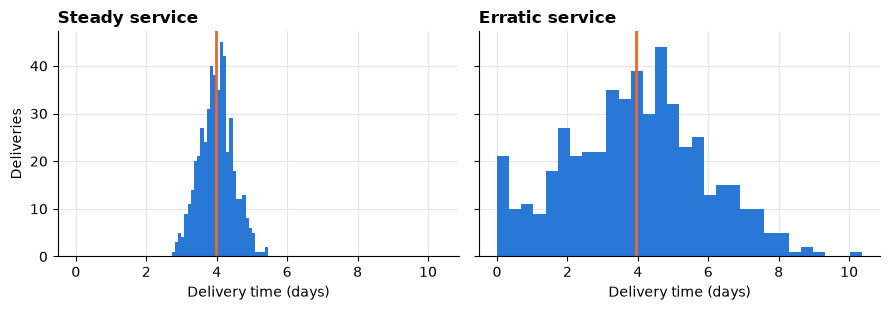

In [5]:
steady = pd.Series(rng.normal(loc=4, scale=0.5, size=500)).clip(lower=0)
erratic = pd.Series(rng.normal(loc=4, scale=2.0, size=500)).clip(lower=0)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharex=True, sharey=True)
for ax, data, title in zip(axes, [steady, erratic], ["Steady service", "Erratic service"]):
    ax.hist(data, bins=30)
    ax.axvline(data.mean(), color="#eb6834", linewidth=2)
    ax.set_title(title)
    ax.set_xlabel("Delivery time (days)")
axes[0].set_ylabel("Deliveries")
plt.tight_layout()
plt.show()

The orange line is the mean. It sits in nearly the same place for both. The difference is the **spread**. Four ways to measure it:

| Measure | Meaning | Resists extreme values? |
|---|---|---|
| **Range** | Largest minus smallest | No: one value changes it |
| **IQR** (interquartile range) | Width of the middle half: 75th percentile minus 25th percentile | Yes |
| **Standard deviation** | Typical distance of a value from the mean | No |
| **Percentiles** | The value below which a given share of the data falls | Yes, apart from the most extreme ones |

In [6]:
def spread(s):
    return pd.Series({
        "mean": s.mean(),
        "range": s.max() - s.min(),
        "IQR": s.quantile(0.75) - s.quantile(0.25),
        "std": s.std(),
        "90th percentile": s.quantile(0.90),
    })

pd.DataFrame({"steady": spread(steady), "erratic": spread(erratic)})

,steady,erratic
mean,3.99,3.94
range,2.74,10.36
IQR,0.63,2.64
std,0.48,1.96
90th percentile,4.60,6.55


Read the table column by column. The means agree; every spread measure tells you the erratic service is less predictable.

**Percentiles speak the language of service promises.** "90% of deliveries arrive within *X* days" is the 90th percentile. A customer cares far more about that than about the average.

> **Check your understanding 2**
>
> 1. Why does the range depend on just two deliveries?
> 2. If you had to promise customers a delivery time, would you quote the mean or a high percentile? Why?

---

## Part 3: Shape — skew and long tails

A distribution's **shape** is how its values are spread out: piled up evenly around the middle, or bunched on one side with a long tail on the other.

| Shape | What it looks like | Typical business example |
|---|---|---|
| **Symmetric** | Mirror image around the middle | Weights of packaged goods, measurement errors |
| **Right-skewed** | Most values small, a long tail of large ones | Order values, incomes, house prices, claim sizes |
| **Left-skewed** | Most values high, a tail of small ones | Scores on an easy test, product lifetimes with early failures |

> **Predict, then reveal**
>
> In a right-skewed distribution, is the mean **above** or **below** the median? Decide, then run the next cell. The orange line is the mean, the dark line the median.

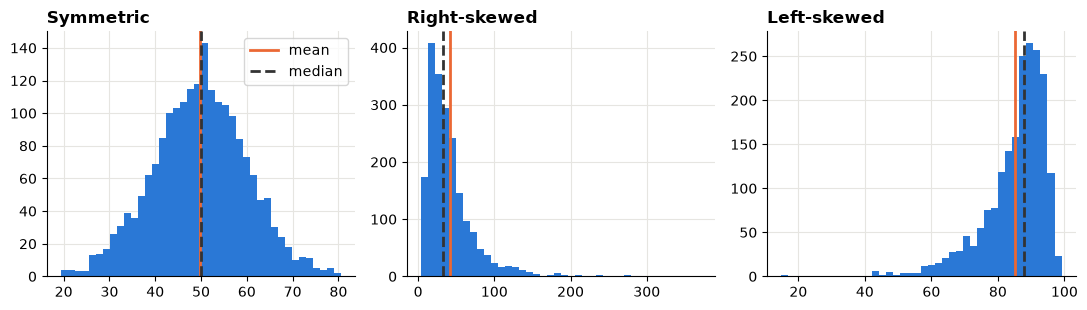

Symmetric     mean   49.8 | median   50.0 | skew -0.03
Right-skewed  mean   41.9 | median   32.7 | skew  2.98
Left-skewed   mean   85.0 | median   87.8 | skew -2.01


In [7]:
shapes = {
    "Symmetric": pd.Series(rng.normal(50, 10, 2000)),
    "Right-skewed": pd.Series(rng.lognormal(mean=3.5, sigma=0.7, size=2000)),
    "Left-skewed": pd.Series(100 - rng.lognormal(mean=2.5, sigma=0.6, size=2000)),
}

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, (title, data) in zip(axes, shapes.items()):
    ax.hist(data, bins=40)
    ax.axvline(data.mean(), color="#eb6834", linewidth=2, label="mean")
    ax.axvline(data.median(), color="#333333", linewidth=2, linestyle="--", label="median")
    ax.set_title(title)
axes[0].legend()
plt.tight_layout()
plt.show()

for title, data in shapes.items():
    print(f"{title:13} mean {data.mean():6.1f} | median {data.median():6.1f} | skew {data.skew():5.2f}")

The long tail **pulls the mean towards it**. So a quick check needs no chart at all:

- mean clearly **above** median → **right** skew (long tail of large values);
- mean clearly **below** median → **left** skew;
- mean close to median → roughly symmetric.

pandas' `.skew()` turns this into one number: near 0 for symmetric data, positive for a right tail, negative for a left tail. Use it as a signal to look at the chart, not as a replacement for it.

> **Check your understanding 3**
>
> A report says "average house price: 420,000; median house price: 350,000". Without a chart, describe the shape of the distribution and say which number better describes a typical house.

---

## Part 4: Three pictures of one distribution

Each chart type answers a different question, and each can hide something.

| Chart | Answers | Watch out for |
|---|---|---|
| **Histogram** | Where do values pile up? | The number of bins changes the story |
| **Box plot** | Where are the middle half, the median and the unusual values? | Hides gaps and double peaks |
| **ECDF** (empirical cumulative distribution) | What share of values is at or below *x*? | Unfamiliar to many readers: label it well |

Here are all three for the right-skewed sample from Part 3:

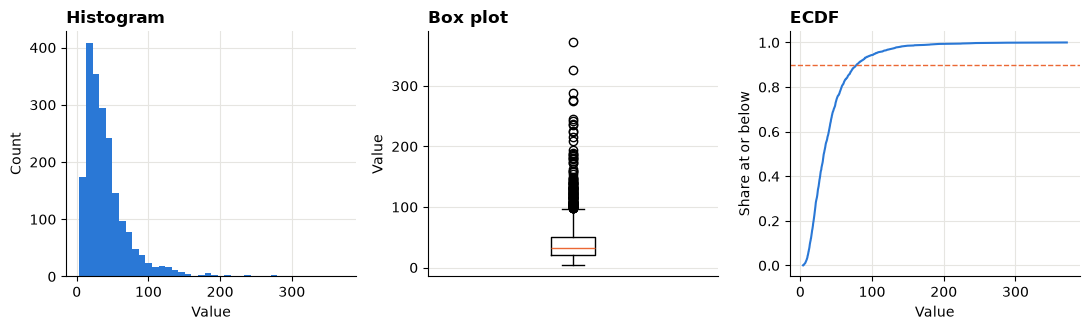

90th percentile: 78.7


In [8]:
data = shapes["Right-skewed"]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))

axes[0].hist(data, bins=40)
axes[0].set_title("Histogram")
axes[0].set_xlabel("Value")
axes[0].set_ylabel("Count")

axes[1].boxplot(data)
axes[1].set_title("Box plot")
axes[1].set_ylabel("Value")
axes[1].set_xticks([])

ecdf_x = np.sort(data)
ecdf_y = np.arange(1, len(data) + 1) / len(data)
axes[2].plot(ecdf_x, ecdf_y)
axes[2].axhline(0.9, color="#eb6834", linestyle="--", linewidth=1)
axes[2].set_title("ECDF")
axes[2].set_xlabel("Value")
axes[2].set_ylabel("Share at or below")

plt.tight_layout()
plt.show()
print("90th percentile:", round(data.quantile(0.9), 1))

How to read them:

1. **Histogram:** bars show how many values fall in each interval. The tall bars on the left and the thin tail on the right are the right skew.
2. **Box plot:** read it from bottom to top. The box spans the 25th to 75th percentiles (the IQR), the line inside is the median, the "whiskers" reach to the furthest values within 1.5 × IQR of the box, and the circles beyond them are values the IQR rule flags (Part 6).
3. **ECDF:** go up to a share on the vertical axis, across to the line, and down to the value. The dashed line at 0.9 crosses the curve at the 90th percentile printed above.

### Predict, then reveal: the number of bins

> **Predict, then reveal**
>
> Will the same data look different with 5 bins and with 100 bins? Run the cell.

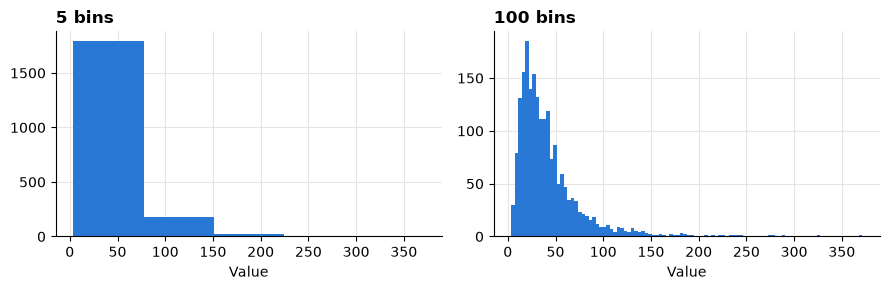

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=False)
for ax, bins in zip(axes, [5, 100]):
    ax.hist(data, bins=bins)
    ax.set_title(f"{bins} bins")
    ax.set_xlabel("Value")
plt.tight_layout()
plt.show()

With too few bins the shape disappears; with too many, random noise looks like structure. Try a few bin counts before choosing one, and never draw conclusions from a single setting.

---

## Part 5: z-scores and the normal curve as a reference

A **z-score** says how many standard deviations a value is from the mean:

**z = (value − mean) ÷ standard deviation**

A z-score of +2 means "two standard deviations above the mean". It lets you compare values measured in different units, such as a delivery time and an order value.

The **normal distribution** is the familiar symmetric bell curve. For data that really are normal, about 68% of values lie within 1 standard deviation of the mean, 95% within 2 and 99.7% within 3. Many people apply this rule to any data. Let us test it on a symmetric and a skewed sample.

In [10]:
def share_within(s, k):
    z = (s - s.mean()) / s.std()
    return (z.abs() <= k).mean()

table = pd.DataFrame({
    "normal reference": [0.683, 0.954, 0.997],
    "symmetric sample": [share_within(shapes["Symmetric"], k) for k in (1, 2, 3)],
    "right-skewed sample": [share_within(shapes["Right-skewed"], k) for k in (1, 2, 3)],
}, index=["within 1 sd", "within 2 sd", "within 3 sd"])
(table * 100).round(1)

,normal reference,symmetric sample,right-skewed sample
within 1 sd,68.30,68.50,87.30
within 2 sd,95.40,95.20,95.60
within 3 sd,99.70,100.00,98.30


The symmetric sample follows the reference closely. The skewed sample does not: its shares differ, and the extreme values sit on one side only.

> **The normal curve is a reference, not an assumption**
>
> Compare your data with the normal curve to learn how it differs. Do not assume business data are normal: order values, waiting times and incomes almost never are. Rules built on the normal curve, such as "anything beyond 3 standard deviations is an outlier", can mislead on skewed data.

> **Check your understanding 4**
>
> An order has a z-score of 4. Is it necessarily an error? What would you check?

---

## Part 6: Unusual values — flag, do not delete

The **IQR rule** marks a value as unusual if it lies more than 1.5 × IQR below the 25th percentile or above the 75th percentile. These limits are called **fences**. It is the rule box plots use, and it works on skewed data because quartiles resist extreme values.

In [11]:
def iqr_fences(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

for title, data in shapes.items():
    low, high = iqr_fences(data)
    flagged = ((data < low) | (data > high)).mean()
    print(f"{title:13} fences {low:7.1f} to {high:7.1f} | flagged {flagged:.1%}")

Symmetric     fences    22.9 to    76.7 | flagged 0.9%
Right-skewed  fences   -25.3 to    96.8 | flagged 6.0%
Left-skewed   fences    65.2 to   107.6 | flagged 4.7%


In the right-skewed sample, the rule flags a noticeable share of values, and **all of them are genuine** draws from the same process. In skewed business data, big orders and long waits are often real and often the most important records.

What to do with a flagged value:

| Finding | Action |
|---|---|
| It is impossible (negative quantity, ship date before order date) | Treat as a data error: correct it from the source or exclude it, and record the change in the preparation log |
| It is possible but rare (a very large order) | **Keep it.** Report robust statistics (median, IQR), and look at the large cases separately |
| You cannot tell | Keep it, flag it, and ask the data owner |

> **Check your understanding 5**
>
> A colleague deletes every order above the upper IQR fence "to clean the data" and then reports total sales. What has gone wrong?

---

## Part 7: Worked case — Superstore orders

The retail table has one row per **order line**. Questions about "a typical order" need one row per **order**. We build that table first and check our grain claim.

In [12]:
# One row per ORDER: add up the lines of each order.
# Segment, ship mode and ship days are the same on every line of an order, so we take the first.
orders = df.groupby("order_id").agg(
    order_value=("sales", "sum"),
    segment=("segment", "first"),
    ship_mode=("ship_mode", "first"),
    ship_days=("order_to_ship_days", "first"),
)

# Check that claim before relying on it: each should be 1.
per_order = df.groupby("order_id")[["segment", "ship_mode", "order_to_ship_days"]].nunique()
print("Most different values inside one order:")
print(per_order.max())
print("Orders:", len(orders))

Most different values inside one order:
segment               1
ship_mode             1
order_to_ship_days    1
dtype: int64
Orders: 3388


Every maximum is 1: each order has one segment, one ship mode and one ship-days value, so taking the first line is safe.

### Step 1: Predict, then reveal — is order value skewed?

> **Predict, then reveal**
>
> Will the mean order value be close to the median, or far above it? Run the cell.

In [13]:
ov = orders["order_value"]
print("Mean:  ", round(ov.mean(), 2))
print("Median:", round(ov.median(), 2))
print("Skew:  ", round(ov.skew(), 2))
ov.quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.99]).to_frame("order value")

Mean:   466.64
Median: 151.46
Skew:   8.86


,order value
0.10,12.96
0.25,38.33
0.50,151.46
0.75,531.66
0.90,"1,181.29"
0.99,"4,256.06"


The mean is far above the median and the skew is strongly positive: a few very large orders pull the mean up. Look at how the percentiles grow faster and faster towards the top.

### Step 2: Picture it

A histogram on an ordinary axis squeezes most orders into the first bar. A second histogram with **logarithmic** bins (each bin a fixed *multiple* wider than the last) spreads the small and large orders out so the shape is visible. The axis labels still show ordinary values.

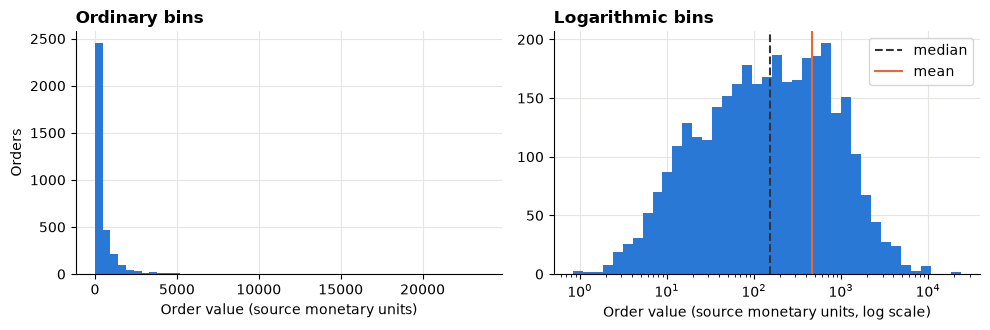

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))

axes[0].hist(ov, bins=50)
axes[0].set_title("Ordinary bins")
axes[0].set_xlabel("Order value (source monetary units)")
axes[0].set_ylabel("Orders")

log_bins = np.logspace(np.log10(ov.min()), np.log10(ov.max()), 40)
axes[1].hist(ov, bins=log_bins)
axes[1].set_xscale("log")
axes[1].axvline(ov.median(), color="#333333", linestyle="--", label="median")
axes[1].axvline(ov.mean(), color="#eb6834", label="mean")
axes[1].set_title("Logarithmic bins")
axes[1].set_xlabel("Order value (source monetary units, log scale)")
axes[1].legend()

plt.tight_layout()
plt.show()

### Step 3: Ship days — a different shape

Ship days take only a few whole-number values, so a bar per value works better than a histogram.

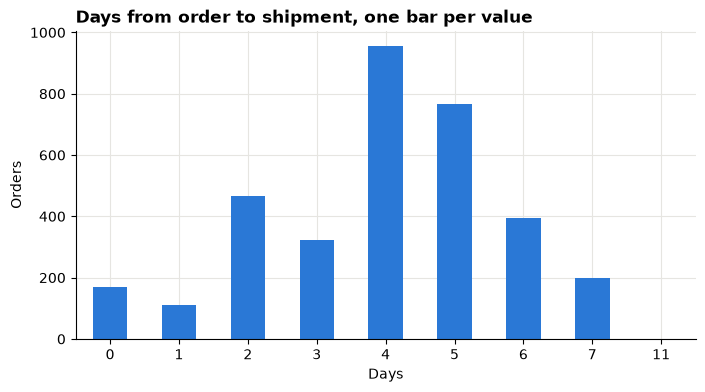

Mean: 3.97 | median: 4.0 | mode: 4
90th percentile: 6.0


In [15]:
sd = orders["ship_days"]
sd.value_counts().sort_index().plot(kind="bar", title="Days from order to shipment, one bar per value")
plt.xlabel("Days")
plt.ylabel("Orders")
plt.xticks(rotation=0)
plt.show()

print("Mean:", round(sd.mean(), 2), "| median:", sd.median(), "| mode:", sd.mode()[0])
print("90th percentile:", sd.quantile(0.9))

Here the mean and median are close, so either is a fair "typical" value. Look carefully at the right end of the chart: is there a value far from all the others? That is a candidate for a flag, and for a question to the operations team, not for deletion.

### Step 4: One summary table for the report

In [16]:
def describe_shape(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return pd.Series({
        "count": s.count(),
        "mean": s.mean(),
        "median": s.median(),
        "std": s.std(),
        "IQR": q3 - q1,
        "90th pct": s.quantile(0.9),
        "skew": s.skew(),
        "flagged by IQR rule": ((s < low) | (s > high)).sum(),
    })

summary = pd.DataFrame({
    "order value (per order)": describe_shape(orders["order_value"]),
    "ship days (per order)": describe_shape(orders["ship_days"]),
})
summary

,order value (per order),ship days (per order)
count,"3,388.00","3,388.00"
mean,466.64,3.97
median,151.46,4.00
std,975.36,1.73
IQR,493.33,2.00
90th pct,"1,181.29",6.00
skew,8.86,-0.42
flagged by IQR rule,305.00,1.00


Reading the table:

- **Order value** is strongly right-skewed: report the **median** with the **IQR** (or percentiles), and mention that a small number of large orders exist.
- **Ship days** is close to symmetric with a few whole-number values: the **mean** or **median** both work, with the **90th percentile** for service promises.

The grain is in the column names on purpose. "Order value per order" and "sales per order line" are different variables with different distributions.

---

## Summary

| Variable looks like… | Centre to report | Spread to report |
|---|---|---|
| Roughly symmetric, no extreme values | Mean (median is similar) | Standard deviation |
| Skewed or with extreme values | Median | IQR or chosen percentiles |
| Categories | Mode (and the share in each category) | Shares of each category |
| A service level or promise | — | A high percentile (90th, 95th) |

Always say **what one row is** before you summarise, always **look at the shape**, and **flag** unusual values instead of deleting them.

---

## Quiz

Answer these at the start of the next lecture. Write short answers.

1. Give one business variable where the median is a better "typical value" than the mean, and explain why.
2. A dataset's mean is 120 and its median is 80. What does this suggest about its shape?
3. Which spread measures resist extreme values, and which do not?
4. What does "the 90th percentile of delivery time is 6 days" mean in plain words?
5. Name one thing a box plot hides that a histogram can show.
6. A value has a z-score of −2.5. What does that mean?
7. Why is "beyond 3 standard deviations = outlier" risky for skewed data?
8. State the IQR rule and say what you should do with a value it flags.

---

## Lab briefing

In the **Lab** you:

1. Build the order-level table and describe order value and ship days.
2. Compare distributions across segments and ship modes with box plots.
3. Explore the long tail of negative profits.
4. Use US Census house prices to see the mean–median gap over four decades.
5. Flag unusual orders with the IQR rule and write a distribution summary table.
6. Debug a colleague's "average order value".

Open the [Session 4 lab](04_descriptive_statistics_lab.md).